In [11]:
import pandas as pd
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

In [12]:
# 1. lod data ARFF
data, meta = arff.loadarff("Dry_Bean_Dataset.arff")
df = pd.DataFrame(data)

for col in df.columns:
    if df[col].dtype == object:
        df[col] = df[col].apply(lambda x: x.decode("utf-8") if isinstance(x, bytes) else str(x))

X = df.iloc[:, :-1].values
y = LabelEncoder().fit_transform(df.iloc[:, -1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ratio data
total_samples = len(df)
train_samples = len(X_train)
test_samples = len(X_test)
train_pct = (train_samples / total_samples) * 100
test_pct = (test_samples / total_samples) * 100

print("=" * 50)
print("📊 Train / Test Split Summary:")
print(f"🔹 Total samples : {total_samples:,} (100.0%)")
print(f"🔹 Train samples : {train_samples:,} ({train_pct:.1f}%)")
print(f"🔸 Test samples  : {test_samples:,} ({test_pct:.1f}%)")
print("=" * 50)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

📊 Train / Test Split Summary:
🔹 Total samples : 13,611 (100.0%)
🔹 Train samples : 10,888 (80.0%)
🔸 Test samples  : 2,723 (20.0%)


In [13]:
import time
from sklearn.ensemble import RandomForestClassifier

#  Random Forest
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=200,   #  num tree
    random_state=42,
    n_jobs=-1
)

#train data (X_train, y_train)
rf.fit(X_train, y_train)
rf_time = time.time() - t0

#(X_test)
rf_pred = rf.predict(X_test)

print("=" * 50)
print("🎉 Random Forest Model trained successfully!")
print("=" * 50)
print(f"⏱️ Training Time: {rf_time:.3f} seconds")
print(f"🎯 Number of predictions generated: {len(rf_pred):,} predictions")
print(f"📊 First 10 predictions of the model: {rf_pred[:10]}")
print("=" * 50)

🎉 Random Forest Model trained successfully!
⏱️ Training Time: 9.987 seconds
🎯 Number of predictions generated: 2,723 predictions
📊 First 10 predictions of the model: [3 1 6 5 0 5 3 6 2 4]


In [8]:
#RMSprop
torch.manual_seed(42)

train_ds = TensorDataset(
    torch.tensor(X_train_scaled, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

rms_net = nn.Sequential(
    nn.Linear(X.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 7)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.RMSprop(rms_net.parameters(), lr=0.001, alpha=0.99)

t0 = time.time()
for epoch in range(40):
    for bx, by in train_loader:
        optimizer.zero_grad()
        loss = criterion(rms_net(bx), by)
        loss.backward()
        optimizer.step()
rms_time = time.time() - t0

with torch.no_grad():
    rms_pred = rms_net(torch.tensor(X_test_scaled, dtype=torch.float32)).argmax(dim=1).numpy()

print(f"RMSprop done in {rms_time:.3f}s | Predictions: {len(rms_pred)}")

RMSprop done in 18.627s | Predictions: 2723


           Model  Accuracy  Macro F1  Time (s)
0  Random Forest    0.9199    0.9321    13.032
1        RMSprop    0.9166    0.9294    18.627


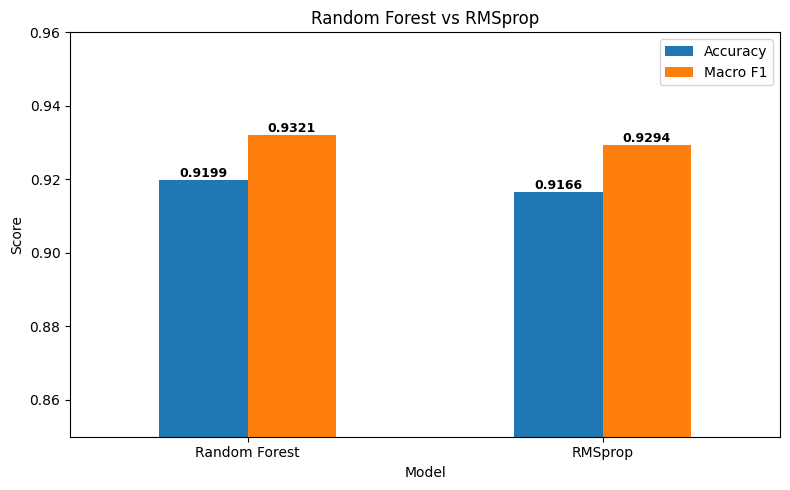

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Random Forest", "RMSprop"],
    "Accuracy": [accuracy_score(y_test, rf_pred), accuracy_score(y_test, rms_pred)],
    "Macro F1": [f1_score(y_test, rf_pred, average="macro"), f1_score(y_test, rms_pred, average="macro")],
    "Time (s)": [round(rf_time, 3), round(rms_time, 3)]
})
print(comparison.round(4))

ax = comparison.plot(x="Model", y=["Accuracy", "Macro F1"], kind="bar", figsize=(8, 5), ylim=(0.85, 0.96))
plt.title("Random Forest vs RMSprop")
plt.ylabel("Score")
plt.xticks(rotation=0)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()